# Assignment: Video Quality Inference

To this point in the class, you have learned various techniques for leading and analyzing packet captures of various types, generating features from those packet captures, and training and evaluating models using those features.

In this assignment, you will put all of this together, using a network traffic trace to train a model to automatically infer video quality of experience from a labeled traffic trace.

## Getting the data

Everything you need is in the course data repository on GitHub, [noise-courses/data](https://github.com/noise-courses/data), under `video-qoe/`. Either clone the whole repository (about 110 MB):

```
git clone https://github.com/noise-courses/data.git
```

or fetch just the files you need with the `wget` lines given in each part below. The four files are:

| File | Used in | Size |
|---|---|---|
| `netflix.pcap` | Part 1 | 22 MB |
| `netflix_dataset.pkl.xz` *or* `video_dataset.pkl.xz` | Part 2 | 22 MB / 61 MB compressed |
| `netflix_session.pkl` | Part 3 | 130 KB |

## Part 1: Warmup

The first part of this assignment builds directly on the hands-on activities but extends them slightly.

### Extract Features from the Network Traffic

Load the `netflix.pcap` file, which is a packet trace that includes network traffic:

```
!wget https://raw.githubusercontent.com/noise-courses/data/main/video-qoe/netflix.pcap
```



In [115]:
import pandas as pd
from netml.pparser.parser import PCAP

pcap = PCAP("data/video-qoe/netflix.pcap", flow_ptks_thres=2)
# Keep missing addresses as None, as netml expects, including with Pandas 3.
with pd.option_context("future.infer_string", False):
    pcap.pcap2pandas()
packets = pcap.df
print(len(packets))
packets.head()

141471


,datetime,dns_query,dns_resp,ip_dst,ip_dst_int,ip_src,ip_src_int,is_dns,length,mac_dst,mac_dst_int,mac_src,mac_src_int,port_dst,port_src,protocol,time,time_normed
0,2018-02-11 08:10:00,"(fonts.gstatic.com.,)",None,128.93.77.234,2.153598e+09,192.168.43.72,3.232247e+09,True,77,a0:ce:c8:0d:2b:a7,176809980013479,e4:ce:8f:01:4c:54,251575813622868,53.0,55697.0,UDP,1518358200.534682,0.000000
1,2018-02-11 08:10:00,"(fonts.gstatic.com.,)",None,128.93.77.234,2.153598e+09,192.168.43.72,3.232247e+09,True,77,a0:ce:c8:0d:2b:a7,176809980013479,e4:ce:8f:01:4c:54,251575813622868,53.0,59884.0,UDP,1518358200.534832,0.000150
2,2018-02-11 08:10:00,"(googleads.g.doubleclick.net.,)",None,128.93.77.234,2.153598e+09,192.168.43.72,3.232247e+09,True,87,a0:ce:c8:0d:2b:a7,176809980013479,e4:ce:8f:01:4c:54,251575813622868,53.0,61223.0,UDP,1518358200.539408,0.004726
3,2018-02-11 08:10:00,"(googleads.g.doubleclick.net.,)",None,128.93.77.234,2.153598e+09,192.168.43.72,3.232247e+09,True,87,a0:ce:c8:0d:2b:a7,176809980013479,e4:ce:8f:01:4c:54,251575813622868,53.0,58785.0,UDP,1518358200.541204,0.006522
4,2018-02-11 08:10:00,"(ytimg.l.google.com.,)",None,128.93.77.234,2.153598e+09,192.168.43.72,3.232247e+09,True,78,a0:ce:c8:0d:2b:a7,176809980013479,e4:ce:8f:01:4c:54,251575813622868,53.0,51938.0,UDP,1518358200.545785,0.011103


### Identifying the Service Type

Use the DNS traffic to filter the packet trace for Netflix traffic.

In [116]:
# netml stores DNS names and responses as one-element tuples.
netflix_dns = packets.loc[
    packets["is_dns"]
    & packets["dns_query"].str[0].str.contains("netflix|nflx", case=False, na=False)
]
netflix_ips = set(netflix_dns["dns_resp"].dropna().str[0])
netflix_packets = packets.loc[
    packets["ip_src"].isin(netflix_ips) | packets["ip_dst"].isin(netflix_ips)
].copy()
print(len(netflix_packets))
netflix_packets.head()

138633


,datetime,dns_query,dns_resp,ip_dst,ip_dst_int,ip_src,ip_src_int,is_dns,length,mac_dst,mac_dst_int,mac_src,mac_src_int,port_dst,port_src,protocol,time,time_normed
107,2018-02-11 08:10:02,None,None,198.38.120.130,3.324410e+09,192.168.43.72,3.232247e+09,False,78,a0:ce:c8:0d:2b:a7,176809980013479,e4:ce:8f:01:4c:54,251575813622868,443.0,58451.0,TCP,1518358202.903273,2.368591
109,2018-02-11 08:10:02,None,None,198.38.120.130,3.324410e+09,192.168.43.72,3.232247e+09,False,78,a0:ce:c8:0d:2b:a7,176809980013479,e4:ce:8f:01:4c:54,251575813622868,443.0,58452.0,TCP,1518358202.903319,2.368637
110,2018-02-11 08:10:02,None,None,198.38.120.130,3.324410e+09,192.168.43.72,3.232247e+09,False,78,a0:ce:c8:0d:2b:a7,176809980013479,e4:ce:8f:01:4c:54,251575813622868,443.0,58453.0,TCP,1518358202.903415,2.368733
112,2018-02-11 08:10:02,None,None,52.19.39.146,8.736705e+08,192.168.43.72,3.232247e+09,False,78,a0:ce:c8:0d:2b:a7,176809980013479,e4:ce:8f:01:4c:54,251575813622868,443.0,58454.0,TCP,1518358202.903625,2.368943
113,2018-02-11 08:10:02,None,None,52.19.39.146,8.736705e+08,192.168.43.72,3.232247e+09,False,78,a0:ce:c8:0d:2b:a7,176809980013479,e4:ce:8f:01:4c:54,251575813622868,443.0,58455.0,TCP,1518358202.903688,2.369006


### Generate Statistics

Generate statistics and features for the Netflix traffic flows. Use the `netml` library or any other technique that you choose to generate a set of features that you think would be good features for your model. 

In [117]:
# Use the longest flow duration as the split interval to keep whole flows.
pcap.pcap2flows(q_interval=1.0)
pcap.flows = [
    (fid, flow_packets) for fid, flow_packets in pcap.flows
    if fid[0] in netflix_ips or fid[1] in netflix_ips
]
pcap.flow2features("STATS", fft=False, header=False)
features = pd.DataFrame(pcap.features, columns=[
    "sub_duration", "pkts_rate", "bytes_rate", "mean", "std",
    "q1", "q2", "q3", "min", "max", "num_pkts", "num_bytes",
])
features.head()

,sub_duration,pkts_rate,bytes_rate,mean,std,q1,q2,q3,min,max,num_pkts,num_bytes
0,14.440177,0.831015,73.683308,88.666667,48.140997,66.0,66.0,69.0,66.0,200.0,12.0,1064.0
1,14.442865,0.761622,69.099863,90.727273,49.772374,66.0,66.0,72.0,66.0,200.0,11.0,998.0
2,14.437420,0.831173,73.697377,88.666667,48.140997,66.0,66.0,69.0,66.0,200.0,12.0,1064.0
3,138.854511,1.497971,184.560082,123.206731,66.443951,66.0,66.0,200.0,54.0,200.0,208.0,25627.0
4,74.817607,0.360878,45.203263,125.259259,66.350692,66.0,66.0,200.0,54.0,200.0,27.0,3382.0


**Write a brief justification for the features that you have chosen.**

Our features are flow duration, packets per second, bytes per second, packet count, total bytes, and various metrics for packet size. These will provide insight into how long traffic lasts, how much data moves, and the distribution of packet sizes. These may help with predicting video quality, since higher resolutions generally require more data (eg. high throughput, large packet sizes, and large amount of data may indicate a bulk video transfer). 

### Inferring Segment downloads

In addition to the features that you could generate using the `netml` library or similar, add to your feature vector a "segment downloads rate" feature, which indicates the number of video segments downloaded for a given time window.

Note: If you are using the `netml` library, generating features with `SAMP` style options may be useful, as this option gives you time windows, and you can then simply add the segment download rate to that existing dataframe.

In [118]:
# Infer segments as downstream TCP payload runs separated by zero-payload packets.
segment_counts = []
for fid, flow_packets in pcap.flows:
    count = 0
    in_segment = False
    if fid[0] in netflix_ips and fid[4] == 6:
        for packet in flow_packets:
            has_payload = len(packet["TCP"].payload) > 0
            count += int(has_payload and not in_segment)
            in_segment = has_payload
    segment_counts.append(count)

# Use each flow's duration as the time window; rates are segments per second.
features["segment_downloads_rate"] = [
    count / duration if duration > 0 else 0
    for count, duration in zip(segment_counts, features["sub_duration"])
]
print(features.shape)
features

(110, 13)


,sub_duration,pkts_rate,bytes_rate,mean,std,q1,q2,q3,min,max,num_pkts,num_bytes,segment_downloads_rate
0,14.440177,0.831015,73.683308,88.666667,48.140997,66.00,66.0,69.0,66.0,200.0,12.0,1064.0,0.000000
1,14.442865,0.761622,69.099863,90.727273,49.772374,66.00,66.0,72.0,66.0,200.0,11.0,998.0,0.000000
2,14.437420,0.831173,73.697377,88.666667,48.140997,66.00,66.0,69.0,66.0,200.0,12.0,1064.0,0.000000
3,138.854511,1.497971,184.560082,123.206731,66.443951,66.00,66.0,200.0,54.0,200.0,208.0,25627.0,0.000000
4,74.817607,0.360878,45.203263,125.259259,66.350692,66.00,66.0,200.0,54.0,200.0,27.0,3382.0,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...
105,11.029823,1.631939,258.390364,158.333333,57.086679,83.25,200.0,200.0,66.0,200.0,18.0,2850.0,0.090663
106,13.252640,3.244637,574.602494,177.093023,47.127642,200.00,200.0,200.0,66.0,200.0,43.0,7615.0,0.150913
107,16.619949,3.249107,588.569793,181.148148,44.436975,200.00,200.0,200.0,66.0,200.0,54.0,9782.0,0.060169
108,6.284040,25.143061,1797.410590,71.487342,25.867662,66.00,66.0,66.0,66.0,200.0,158.0,11295.0,0.000000


## Part 2: Video Quality Inference

You will now load the complete video dataset from a previous study to train and test models based on these features to automatically infer the quality of a streaming video flow.

For this part of the assignment, you will need two pickle files. They are hosted in the course data repository on GitHub, [noise-courses/data](https://github.com/noise-courses/data), in the `video-qoe/` directory. Download them by running the code below:

```
!wget https://raw.githubusercontent.com/noise-courses/data/main/video-qoe/netflix_session.pkl
!wget https://raw.githubusercontent.com/noise-courses/data/main/video-qoe/video_dataset.pkl.xz
!xz -d video_dataset.pkl.xz
```

The dataset is stored xz-compressed in the repository (61 MB compressed, about 265 MB uncompressed), so the last line decompresses it. If `xz` is not available on your system, you can decompress it in Python instead:

```python
import lzma, shutil
with lzma.open('video_dataset.pkl.xz') as f_in, open('video_dataset.pkl', 'wb') as f_out:
    shutil.copyfileobj(f_in, f_out)
```

A smaller Netflix-only dataset (`netflix_dataset.pkl.xz`, 52,279 samples with 251 features) is available in the same directory and may be used instead of the multi-service `video_dataset.pkl` (204,713 samples with 170 features).

**Backup (Google Drive):** If GitHub is unavailable, the Netflix-only dataset is also mirrored on Google Drive. This link only works through `gdown` (`pip install gdown`); opening it with `wget`, `curl`, or a browser returns a virus-scan HTML page instead of the file:

```
!gdown 'https://drive.google.com/uc?id=1iI1tos08p9FJBI-ADR9b_iFObWRwXANX' -O netflix_dataset.pkl
```

### Load the File

Load the video dataset pickle file.

In [119]:
import lzma
import pickle

with lzma.open("data/video-qoe/video_dataset.pkl.xz", "rb") as f:
    video_data = pickle.load(f, encoding="latin1")
video_data.head()

,L7_10_avg_chunksize,L7_10_chunksizes_50,L7_10_chunksizes_75,L7_10_chunksizes_85,L7_10_chunksizes_90,L7_10_max_chunksize,L7_10_min_chunksize,L7_10_std_chunksize,absolute_timestamp,L7_all_prev_down_chunk_iat_50,...,L4_userStdRTT,L4_userStdRetransmit,L4_userStdRwnd,L4_userStrBytesInFlight,L4_userSynFlags,L4_userTwoRetransmit,L4_userUrgFlags,L4_userXRetransmit,L4_userZeroRetransmit,service
0,148947.1,43473.0,185098.0,361832.3,461040.2,539882,4380,185126.042201,1.548881e+09,161.5,...,19684.624818,57.462837,985.136457,0,4,0.0,0,0.108730,0.557937,netflix
1,91984.2,101882.0,122323.0,159843.4,181011.8,196778,24498,62449.107359,1.548881e+09,361.0,...,8183.942278,71.011784,310.123152,0,1,0.0,0,0.116865,0.549802,netflix
2,147725.0,111373.0,224157.0,286280.0,325845.8,396800,24498,134268.559725,1.548881e+09,337.0,...,7087.849223,85.198800,149.669427,0,0,0.0,0,0.126852,0.539815,netflix
3,246420.6,297522.0,330737.5,361030.7,378404.0,396800,24498,127394.372454,1.548881e+09,399.0,...,56963.445789,109.397055,14006.713648,0,1,0.0,0,0.186111,0.480556,netflix
4,336681.0,354461.0,399719.5,409866.3,414060.0,438000,198238,79844.367998,1.548881e+09,414.0,...,10988.579443,122.132897,13261.305817,0,0,0.0,0,0.194444,0.472222,netflix


### Clean the File

1. The dataset contains video resolutions that are not valid. Remove entries in the dataset that do not contain a valid video resolution. Valid resolutions are 240, 360, 480, 720, 1080.

In [120]:
video_data = video_data[
    video_data["resolution"].isin([240, 360, 480, 720, 1080])
].copy()
video_data.shape

(200063, 170)

2. The file also contains columns that are unnecessary (in fact, unhelpful!) for performing predictions. Identify those columns, and remove them.

In [121]:
session_ids = video_data["session_id"]
video_data = video_data.drop(columns=[
    "index", "home_id", "session_id", "video_id", "service",
    "absolute_timestamp", "relative_timestamp", "video_position",
    "L4_serverUrgFlags", "L4_userUrgFlags"
])
video_data.head()

,L7_10_avg_chunksize,L7_10_chunksizes_50,L7_10_chunksizes_75,L7_10_chunksizes_85,L7_10_chunksizes_90,L7_10_max_chunksize,L7_10_min_chunksize,L7_10_std_chunksize,L7_all_prev_down_chunk_iat_50,L7_all_prev_down_chunk_iat_75,...,L4_userStdBytesInFlight,L4_userStdBytesPerPacket,L4_userStdRTT,L4_userStdRetransmit,L4_userStdRwnd,L4_userStrBytesInFlight,L4_userSynFlags,L4_userTwoRetransmit,L4_userXRetransmit,L4_userZeroRetransmit
0,148947.1,43473.0,185098.0,361832.3,461040.2,539882,4380,185126.042201,161.5,602.50,...,330.414175,94.051096,19684.624818,57.462837,985.136457,0,4,0.0,0.108730,0.557937
1,91984.2,101882.0,122323.0,159843.4,181011.8,196778,24498,62449.107359,361.0,614.00,...,361.139739,119.846893,8183.942278,71.011784,310.123152,0,1,0.0,0.116865,0.549802
2,147725.0,111373.0,224157.0,286280.0,325845.8,396800,24498,134268.559725,337.0,620.00,...,361.942841,111.889532,7087.849223,85.198800,149.669427,0,0,0.0,0.126852,0.539815
3,246420.6,297522.0,330737.5,361030.7,378404.0,396800,24498,127394.372454,399.0,652.00,...,363.797811,79.787976,56963.445789,109.397055,14006.713648,0,1,0.0,0.186111,0.480556
4,336681.0,354461.0,399719.5,409866.3,414060.0,438000,198238,79844.367998,414.0,782.25,...,377.300424,65.877408,10988.579443,122.132897,13261.305817,0,0,0.0,0.194444,0.472222


**Briefly explain why you removed those columns.**

We drop index because it is only a row number. We remove home_id, session_id, and video_id because these identifiers may encourage memorizing particular households or recordings rather than learning traffic patterns. We exclude timestamps and playback position to avoid relying on recording time or playback context, and remove service to focus predictions on traffic measurements rather than service identity. Finally, L4_serverUrgFlags and L4_userUrgFlags are always zero, so they provide no variation for distinguishing resolutions.

### Prepare Your Data

Prepare your data matrix, determine your features and labels, and perform a train-test split on your data.

In [122]:
from sklearn.model_selection import GroupShuffleSplit

X = video_data.drop(columns="resolution")
y = video_data["resolution"].astype(int)
split = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_index, test_index = next(split.split(X, y, groups=session_ids))
X_train, X_test = X.iloc[train_index], X.iloc[test_index]
y_train, y_test = y.iloc[train_index], y.iloc[test_index]
X_train.shape, X_test.shape

((159795, 159), (40268, 159))

### Train and Tune Your Model

1. Select a model of your choice.
2. Train the model using your training data.

In [123]:
from sklearn.tree import DecisionTreeClassifier

model = DecisionTreeClassifier(random_state=42)
model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

### Tune Your Model

Perform hyperparameter tuning to find optimal parameters for your model.

In [124]:
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold

param_grid = {
    "max_depth": [10, 20, None],
    "min_samples_leaf": [1, 5, 10],
    "criterion": ["gini", "entropy"],
}
cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=42)
search = GridSearchCV(model, param_grid, scoring="f1_macro", cv=cv, n_jobs=2)
search.fit(X_train, y_train, groups=session_ids.iloc[train_index])
model = search.best_estimator_
print("Best parameters:", search.best_params_)
print("Best CV macro F1:", search.best_score_)

Best parameters: {'criterion': 'gini', 'max_depth': 20, 'min_samples_leaf': 10}
Best CV macro F1: 0.8515790053017468


### Evaluate Your Model

Evaluate your model accuracy according to the following metrics:

1. Accuracy
2. F1 Score
3. Confusion Matrix
4. ROC/AUC

Accuracy: 0.8688040131121486
Macro F1: 0.8568632612470916
Macro ROC AUC: 0.9394650506204199


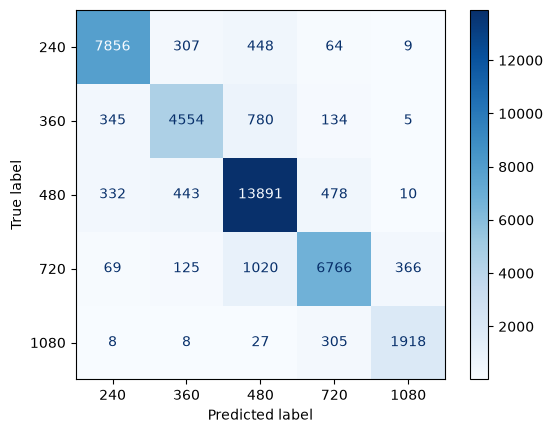

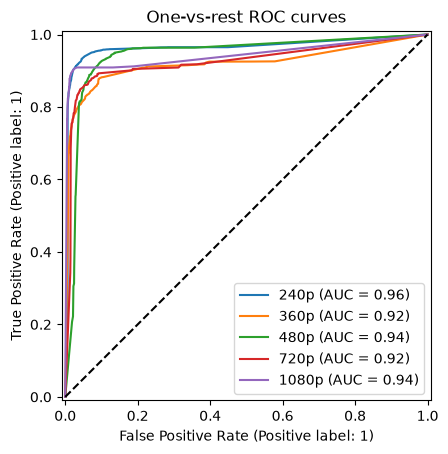

In [125]:
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score, f1_score, roc_auc_score,
    ConfusionMatrixDisplay, RocCurveDisplay,
)
from sklearn.preprocessing import label_binarize

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Macro F1:", f1_score(y_test, y_pred, average="macro"))
print("Macro ROC AUC:", roc_auc_score(
    y_test, y_prob, labels=model.classes_, multi_class="ovr", average="macro"
))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, labels=model.classes_, cmap="Blues"
)
y_binary = label_binarize(y_test, classes=model.classes_)
fig, ax = plt.subplots()
for i, resolution in enumerate(model.classes_):
    RocCurveDisplay.from_predictions(
        y_binary[:, i], y_prob[:, i], name=f"{resolution}p", ax=ax
    )
ax.plot([0, 1], [0, 1], "k--")
ax.set_title("One-vs-rest ROC curves")
plt.show()

## Part 3: Predict the Ongoing Resolution of a Real Netflix Session

Now that you have your model, it's time to put it in practice!

Use a preprocessed Netflix video session to infer **and plot** the resolution at 10-second time intervals. The session is `netflix_session.pkl` (downloaded in Part 2 above; 59 ten-second windows with the same 251 features as `netflix_dataset.pkl`, plus the true `resolution` so you can check yourself):

```python
session = pd.read_pickle('netflix_session.pkl')
```

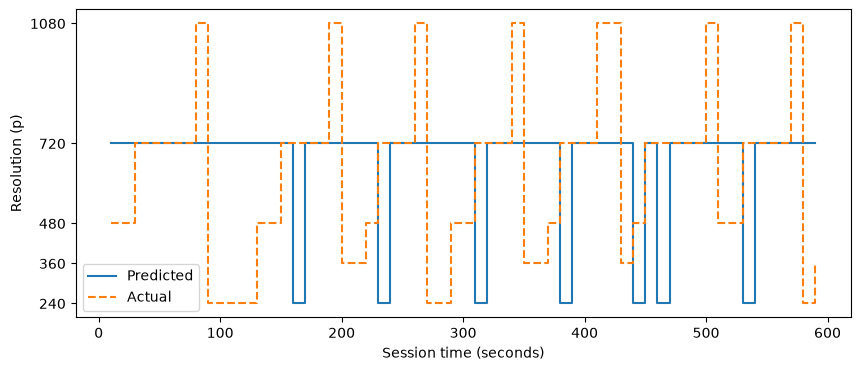

In [126]:
session = pd.read_pickle("data/video-qoe/netflix_session.pkl")
# Session feature names omit the L3_, L4_, and L7_ prefixes.
session_X = session[[column.split("_", 1)[1] for column in X.columns]].copy()
session_X.columns = X.columns
session["predicted_resolution"] = model.predict(session_X)

plt.figure(figsize=(10, 4))
plt.step(session["relative_timestamp"], session["predicted_resolution"],
         where="post", label="Predicted")
plt.step(session["relative_timestamp"], session["resolution"],
         where="post", label="Actual", linestyle="--")
plt.xlabel("Session time (seconds)")
plt.ylabel("Resolution (p)")
plt.yticks([240, 360, 480, 720, 1080])
plt.legend()
plt.show()

## Acknowledgments

Please fill in the following before submitting.

**Collaborators:** (people you discussed the assignment with, or "none")
Justin Wang

**Outside sources and code:** (documentation, blog posts, repositories, etc., with links, or "none")

**AI tools used:** (which tool, and roughly how, e.g., "Claude Code for the netml feature extraction and debugging the pickle load", or "none")
Used Codex for segment downloads implementation, model evaluation, and general debugging

**Prompts (optional):** if you're willing, add a `prompts.md` next to this notebook with the prompts you used. This is not graded; it helps improve the course.